In [ ]:
import pandas as pd

In [25]:
df = pd.read_csv("/content/creditcard.csv")

In [26]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


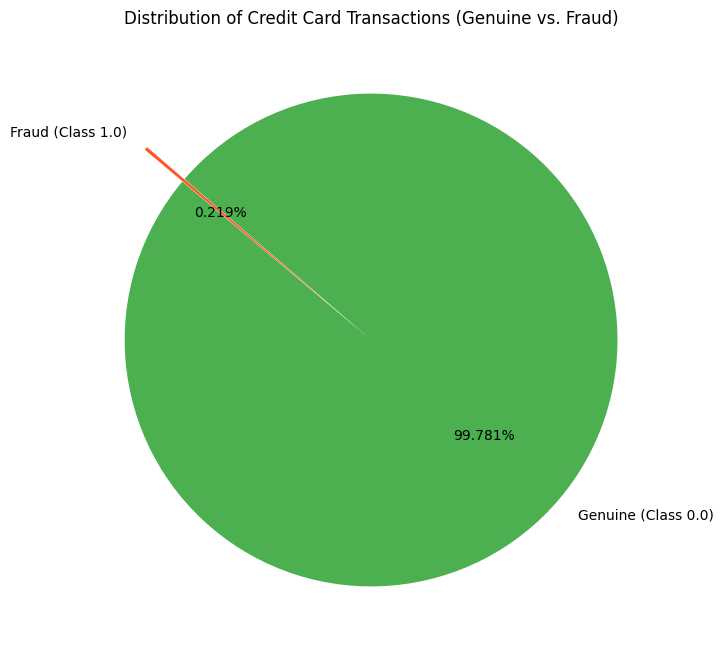

In [ ]:
import matplotlib.pyplot as plt

# Calculate class distribution on the clean dataset
class_counts = clean_df['Class'].value_counts()
labels = ['Genuine (Class 0.0)', 'Fraud (Class 1.0)']

# Plotting the pie chart
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    class_counts,
    labels=labels,
    autopct='%1.3f%%',
    startangle=140,
    colors=['#4CAF50', '#FF5722'],
    explode=(0, 0.2)
)
ax.set_title('Distribution of Credit Card Transactions (Genuine vs. Fraud)')
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Input your custom transaction values here to test the model:
custom_data = {
    'Time': 85000.0,
    'Amount': 250.0, # Transaction amount in dollars

    # Features V1 to V28 are the PCA features. You can modify these to test scenarios:
    'V1': -1.35, 'V2': -0.07, 'V3': 2.53, 'V4': 1.37, 'V5': -0.33,
    'V6': 0.46, 'V7': 0.23, 'V8': 0.09, 'V9': 0.36, 'V10': 0.09,
    'V11': -0.55, 'V12': -0.61, 'V13': 0.99, 'V14': -0.31, 'V15': 1.46,
    'V16': -0.47, 'V17': 0.74, 'V18': 0.03, 'V19': 0.80, 'V20': 0.25,
    'V21': -0.01, 'V22': 0.27, 'V23': -0.11, 'V24': 0.06, 'V25': 0.12,
    'V26': -0.18, 'V27': 0.13, 'V28': -0.02
}

# Convert the custom input into a DataFrame with correct feature order
custom_df = pd.DataFrame([custom_data])
custom_df = custom_df[X_train.columns]

# Make prediction
prediction = model.predict(custom_df)[0]
prediction_proba = model.predict_proba(custom_df)[0]

print("--- Custom Transaction Test Result ---")
if prediction == 1.0:
    print(f"Result: ⚠️ FRAUD DETECTED (Class 1.0) with {prediction_proba[1]:.2%} confidence.")
else:
    print(f"Result: ✅ GENUINE TRANSACTION (Class 0.0) with {prediction_proba[0]:.2%} confidence.")

--- Custom Transaction Test Result ---
Result: ✅ GENUINE TRANSACTION (Class 0.0) with 100.00% confidence.


In [ ]:
from sklearn.model_selection import train_test_split

# Filter out any incomplete or NaN rows in the loaded dataset
clean_df = df.dropna()

# Separate features (X) and target labels (y)
X = clean_df.drop(columns=['Class'])
y = clean_df['Class']

# Split the dataset into 80% train and 20% test, stratifying to preserve class ratios
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 123696 samples
Testing set size: 30924 samples


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Initialize the Random Forest model with balanced class weights
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)

# Train the model
print("Training the model on the 80% training set...")
model.fit(X_train, y_train)

# Make predictions on the 20% test set
y_pred = model.predict(X_test)

# Display evaluation metrics
print("\n--- Classification Report (20% Test Set) ---")
print(classification_report(y_test, y_pred))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

Training the model on the 80% training set...

--- Classification Report (20% Test Set) ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     30856
         1.0       0.98      0.79      0.88        68

    accuracy                           1.00     30924
   macro avg       0.99      0.90      0.94     30924
weighted avg       1.00      1.00      1.00     30924

--- Confusion Matrix ---
[[30855     1]
 [   14    54]]
